# 05 De principio a fin con falcondale-sdk: que la máquina elija el modelo

En los cuadernos `01` a `04` hicimos cada paso a mano: escalar, elegir el mapa, medir el *target alignment*, entrenar el QSVM, contar circuitos y hasta medir el kernel en IBM. Aquí hacemos lo contrario a propósito: le damos un dataset nuevo a [falcondale-sdk](https://falcondale.readthedocs.io/) y dejamos que su clase `Project` perfile los datos, juzgue si merece la pena probar QML, recorte rasgos resolviendo un QUBO y entrene el modelo que ella misma recomienda con `evaluate("auto")`.

La pregunta ya no es "¿cómo se programa un QSVC?", sino "¿qué decide la herramienta cuando nadie le dice qué modelo usar, y estamos de acuerdo con su decisión?".

Referencias: [documentación de falcondale-sdk](https://falcondale.readthedocs.io/), su cuaderno *QML assessment* y el cuaderno `01` de esta sesión (el mismo QSVM, hecho a mano).


In [1]:
import importlib.util

# En Colab (o cualquier entorno sin el SDK) esto lo instala; si ya está, no toca nada.
if importlib.util.find_spec('falcondale') is None:
    !pip install -q "falcondale[qml,feature-selection]" matplotlib pylatexenc
else:
    import falcondale
    print('falcondale-sdk ya instalado, versión', falcondale.__version__)


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


## 1. Un dataset particular: cáncer de mama de Wisconsin

Cambiamos de dataset para no hacernos trampas: 569 tumores descritos con 30 rasgos numéricos (radio, textura, perímetro, área... en su versión media, error y *worst*) y una etiqueta binaria. Ojo con la codificación de sklearn: `0` es maligno y `1` es benigno.

30 rasgos son un problema inmediato para lo que sabemos: un QSVC de un qubit por rasgo pediría 30 qubits, por encima del presupuesto de 16 del kernel en simulador. Ese choque es justo lo que queremos que la herramienta detecte sola.


In [2]:
from sklearn import datasets

X, y = datasets.load_breast_cancer(return_X_y=True, as_frame=True)
data = X.assign(target=y)
print(f'{data.shape[0]} muestras x {data.shape[1] - 1} rasgos')
print('Clases (0 = maligno, 1 = benigno):', y.value_counts().to_dict())
data.head(3)

569 muestras x 30 rasgos
Clases (0 = maligno, 1 = benigno): {1: 357, 0: 212}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0


## 2. El proyecto: perfilar y preprocesar

`Project` envuelve el dataset y lleva la cuenta de su estado. `profile_dataset()` es el chequeo que en los otros cuadernos hacíamos mirando gráficos: valores perdidos, columnas constantes o no numéricas y balance de clases. `preprocess()` rellena huecos y escala, el mismo paso que nuestro `MinMaxScaler` manual, pero sin tener que acordarse.


In [3]:
from falcondale import Project

project = Project(data, target='target')
perfil = project.profile_dataset()

Number of samples on the dataset: 569
Number of columns on the dataset: 31
target has been selected as target variable for supervised learning tasks.
Target class balance: 1: 62.7%, 0: 37.3%
Ratio of cells with missing values: 0.00%
All data is numeric therefore little preprocessing might need to be done.


In [4]:
project.preprocess()
print('Rasgos tras preprocesar:', project.show_features().shape)
project.show_features().head(3)

Rasgos tras preprocesar: (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,0.521037,0.022658,0.545989,0.363733,0.593753,0.792037,0.703140,0.731113,0.686364,0.605518,...,0.620776,0.141525,0.668310,0.450698,0.601136,0.619292,0.568610,0.912027,0.598462,0.418864
1,0.643144,0.272574,0.615783,0.501591,0.289880,0.181768,0.203608,0.348757,0.379798,0.141323,...,0.606901,0.303571,0.539818,0.435214,0.347553,0.154563,0.192971,0.639175,0.233590,0.222878
2,0.601496,0.390260,0.595743,0.449417,0.514309,0.431017,0.462512,0.635686,0.509596,0.211247,...,0.556386,0.360075,0.508442,0.374508,0.483590,0.385375,0.359744,0.835052,0.403706,0.213433


## 3. ¿Merece la pena probar QML aquí? `assess()`

El assessor combina varias señales que ya conocemos por separado: cuántas frecuencias necesita la frontera de decisión y si un circuito codificado en ángulo puede expresarlas (idea de Fourier de los mapas de rasgos), qué profundidad haría falta, si un modelo lineal clásico ya resuelve el problema (nuestro "¿para qué pagar circuitos?") y si las clases están equilibradas.

Primero evaluamos los 30 rasgos tal cual. Fíjate en dos cosas: la nota global y qué modelo queda descartado por inviable, no por malo.


In [5]:
assessment = project.assess()
assessment.report()

╭─ QML suitability ───────────────────────────────────────────────────────────────────────────────────────────────╮
│ 66.0 / 100   MEDIUM  Quantum models might help, with care                                                       │
│ 569 of 569 samples, 30 of 30 features, 2 classes, budget of 16 qubits                                           │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─ Sub-scores ────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Fourier approx.     ━━━━━━━━━━━━━━━━━━━━╸━     94  average R² 0.781                                             │
│ Trainability        ━━━━━━━━━━━━━━━╸━━━━━━     72  28.0% of frequencies unreachable (ternary init)              │
│ Circuit depth       ━━━━━━━━━━━━━╺━━━━━━━━     60  fixed frequency depth ≈ 1344                                 │
│ Classical hardness  ━━━╸━━━━━━━━━━━━━━━━━━     17  logistic bal. acc. 0.966, tree gap -0.055                    │
│ Class balance       ━━━━━━━━━━━━━━━╸━━━━━━     71  ratio 0.594 (mild)                                           │
│ Dimensionality      ━━━━━━━━━━━━━━━━━━━━━━    100  ≥ 7 qubits needed                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
Classical baseline (3 fold, out of fold)                                                                           
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┓
┃ Model                           ┃          Bal. accuracy ┃       Precision ┃      Recall ┃        F1 ┃      AUC ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━┩
│ Logistic regression             │                  0.966 │           0.970 │       0.983 │     0.976 │    0.991 │
│ Decision tree                   │                  0.910 │           0.931 │       0.938 │     0.934 │    0.917 │
└─────────────────────────────────┴────────────────────────┴─────────────────┴─────────────┴───────────┴──────────┘
Spectrum                                  
┌─────────────────────────────┬──────────┐
│ Features showing signal     │ 28 of 30 │
│ Highest frequency ω         │       12 │
│ Significant frequencies K   │       75 │
│ Unreachable, zero init      │    61.3% │
│ Unreachable, ternary init   │    28.0% │
├─────────────────────────────┼──────────┤
│ RBF kernel effective rank   │     6.37 │
│ RBF kernel spectral gap     │    7.793 │
│ RBF kernel condition number │ 1.92e+09 │
└─────────────────────────────┴──────────┘
Most oscillating features                                                                                          
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Feature                                             ┃       ω ┃     K ┃           R² ┃              Unreachable ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ smoothness error                                    │      12 │     1 │        0.170 │                      1/1 │
│ worst fractal dimension                             │       8 │     3 │        0.711 │                      1/3 │
│ compactness error                                   │       6 │     2 │        0.720 │                      1/2 │
│ mean area                                           │       5 │     3 │        0.891 │                      1/3 │
│ worst area                                          │       5 │     3 │        0.917 │                      1/3 │
│ mean symmetry                                       │       4 │     4 │        0.755 │                      2/4 │
│ perimeter error                                     │       4 │     4 │        0.833 │                      2/4 │
│ co

In [6]:
print(f'Nota QML: {assessment.score_}/100 ({assessment.verdict_})')
print('Sub-notas:', assessment.sub_scores_)
for rec in assessment.recommendations_:
    print(f'{rec.name:<28} nota {rec.score:5.1f}  qubits {rec.qubits:2d}  viable={rec.feasible}  {rec.reasons[0]}')
print()
print('Consejos:')
for consejo in assessment.advice():
    print(' -', consejo)

Nota QML: 66.0/100 (MEDIUM)
Sub-notas: {'fourier': 93.8, 'trainability': 72.0, 'depth': 60.0, 'difficulty': 17.2, 'imbalance': 71.3, 'dimensionality': 100.0}
svc                          nota  82.8  qubits  0  viable=True  classical baseline, overall QML suitability is medium
qnn                          nota  68.2  qubits  5  viable=True  amplitude embedding fits 30 features in 5 qubits
qsvc (backend=pennylane)     nota   0.0  qubits 30  viable=False  needs 30 qubits, budget is 16
qsvc (backend=qiskit)        nota   0.0  qubits 30  viable=False  needs 30 qubits, budget is 16

Consejos:
 - A linear model already solves the task, a quantum kernel is unlikely to add value.
 - 2 features show no signal along their axis, feature_selection() could drop them.
 - Too many features for one qubit per feature, select features to try QSVC.


## 4. Recortar rasgos resolviendo un QUBO: `feature_selection()`

El consejo anterior era literal: sobran rasgos. La selección de rasgos de falcondale plantea un QUBO que premia rasgos informativos y castiga pares redundantes, el mismo tipo de problema que optimizamos en la sesión 02, y lo resuelve aquí con recocido simulado (`method="sa"`).

Pedimos 4 rasgos: bastantes para clasificar, pocos para que el QSVC entre en 4 qubits y se pueda comparar con el cuaderno `04`.


In [7]:
features = project.feature_selection(max_cols=4, method='sa', seed=0)
print('Rasgos elegidos:', features)
print('El proyecto ahora trabaja con:', project.show_features().shape)

Rasgos elegidos: ['mean concave points', 'area error', 'worst radius', 'worst texture']
El proyecto ahora trabaja con: (569, 4)


## 5. Segunda evaluación: ahora sí cabe un modelo cuántico

Repetimos `assess()` avisando del presupuesto real, 4 qubits. La nota y el ranking deberían cambiar: lo que antes era inviable ahora puede entrenarse. Esto es exactamente la decisión que en el cuaderno `01` tomábamos a ojo mirando el *target alignment*.


In [8]:
assessment = project.assess(n_qubits=4)
print(f'Nota QML: {assessment.score_}/100 ({assessment.verdict_})')
for rec in assessment.recommendations_:
    print(f'{rec.name:<28} nota {rec.score:5.1f}  qubits {rec.qubits:2d}  viable={rec.feasible}  {rec.reasons[0]}')
print('Modelo recomendado:', assessment.best_model.name)

Nota QML: 74.9/100 (HIGH)
qsvc (backend=qiskit)        nota  90.0  qubits  4  viable=True  100% of the frequencies within reach of a repeated encoding
svc                          nota  81.1  qubits  0  viable=True  classical baseline, overall QML suitability is high
qsvc (backend=pennylane)     nota  72.0  qubits  4  viable=True  50% of the frequencies within reach of a single rotation
qnn                          nota  65.6  qubits  2  viable=True  amplitude embedding fits 4 features in 2 qubits
Modelo recomendado: qsvc (backend=qiskit)


## 6. Entrenar sin elegir: `evaluate("auto")`

`evaluate("auto")` entrena el modelo mejor clasificado por la evaluación (y vuelve a evaluar sola si los rasgos cambiaron desde la última vez). Debajo sigue siendo nuestro conocido: split train/test, un `QSVC` con kernel de fidelidad calculado en simulador y métricas de sklearn. Lo automático es la cadena de decisiones, no la física.

Entrenamos también el `svc` clásico como línea de base honesta, la misma comparación que la herramienta hace por dentro al puntuar la dificultad.


In [9]:
model = project.evaluate('auto')
print('Tipo entrenado:', model.type)
model.print_report()

Assessment recommends qsvc (backend=qiskit): 100% of the frequencies within reach of a repeated encoding
Tipo entrenado: qsvc
              precision    recall  f1-score   support

           0       0.93      0.88      0.90        64
           1       0.93      0.96      0.94       107

    accuracy                           0.93       171
   macro avg       0.93      0.92      0.92       171
weighted avg       0.93      0.93      0.93       171



In [10]:
baseline = project.evaluate('svc')

In [11]:
import pandas as pd

metricas = model.list_metrics()
comparativa = pd.DataFrame({
    model.type: [model.metric(m) for m in metricas],
    'svc (clásico)': [baseline.metric(m) for m in metricas],
}, index=metricas).round(3)
comparativa

,qsvc,svc (clásico)
recall,0.963,0.963
precision,0.928,0.972
f1,0.945,0.967
accuracy,0.930,0.959
balanced accuracy,0.919,0.958
auc,0.975,0.995
specificity,0.875,0.953


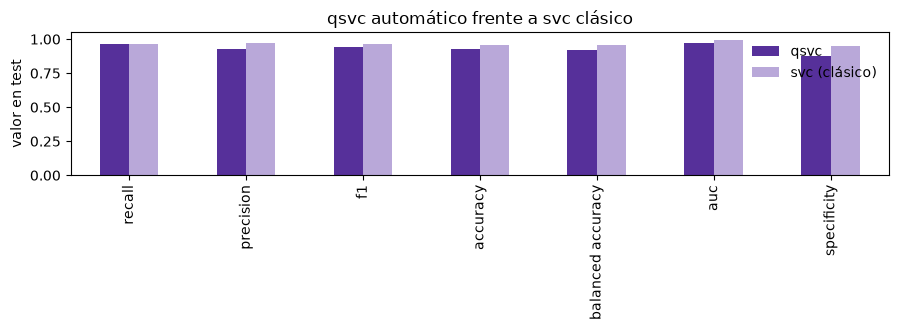

In [12]:
import matplotlib.pyplot as plt

comparativa.plot.bar(figsize=(9, 3.4), color=['#56309a', '#b9a8d9'])
plt.ylim(0, 1.05)
plt.ylabel('valor en test')
plt.title(f'{model.type} automático frente a svc clásico')
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

## 7. Guardar el modelo y usarlo con datos crudos

El objeto `Model` guarda también el preprocesado, así que predice directamente sobre filas con las columnas originales, sin reescalar a mano. Guardamos, recargamos y comprobamos que las predicciones coinciden.


In [13]:
model.save('modelo-auto.pkl')
cargado = Project.load_model('modelo-auto.pkl')

nuevos = data.drop(columns=['target']).head(5)
print('Predicciones (0 = maligno, 1 = benigno):', cargado.predict(nuevos))
print('Etiquetas reales:                    ', y.head(5).to_numpy())
print('Probabilidad de benigno:', cargado.predict_proba(nuevos).round(3))

Predicciones (0 = maligno, 1 = benigno): [0 0 0 0 0]
Etiquetas reales:                     [0 0 0 0 0]
Probabilidad de benigno: [0.    0.023 0.003 0.002 0.092]


## 8. Qué ha automatizado el SDK y qué no

Lo que te quita de encima: el perfilado, el escalado, la selección de rasgos como QUBO, un juicio reproducible sobre si QML tiene sentido aquí (con sus razones escritas) y el entrenamiento con su comparación clásica. Es, en una llamada, el recorrido de los cuadernos `01` a `03`.

Lo que no cambia: el kernel cuántico se sigue calculando en simulador (nada de esto ha tocado la QPU del cuaderno `04`), la evaluación es una heurística con pesos elegidos por los autores y no una garantía, y el veredicto final en este dataset es incómodo pero sano: el modelo cuántico automático clasifica bien y aun así el `svc` clásico le gana en casi todas las métricas. Que una herramienta te diga cuándo *no* necesitas lo cuántico es parte de su valor.


## Para clase

- Entrena `project.evaluate('qnn')` con los mismos 4 rasgos y añade su fila a la comparativa. ¿Compensa entrenar el circuito frente al kernel fijo?
- Repite la selección con `max_cols=8` y vuelve a evaluar. ¿Mejora el modelo automático o solo crece el coste del kernel?
- Prueba el flujo completo con un dataset pensado para kernels, por ejemplo `datasets.make_circles(400, noise=0.08, factor=0.5)`: ¿qué nota da `assess()` antes de seleccionar nada y qué modelo elige `auto`?
- Discute los pesos del assessor: si un modelo lineal ya acierta el 97%, ¿qué nota QML pondrías tú y por qué?
